# Zero-shot time-series forecasting on six fresh series

Chronos-2 had 0.860 relative MAE (14.0% less error than seasonal naive) at 512 observations; the best baseline, AutoETS, had 0.961. Its nominal 80% interval coverage averaged 67.4% across series and horizons. These are six selected series, with overlapping origins, so the ranking is a result for these six series.

Question: do seven hosted time-series foundation models beat five fitted or seasonal baselines without task-specific training? We forecast electricity demand, temperature, wind, two page-view series and USD/CAD. Targets are August 20 to October 17, 2026; earlier observations are inputs only. There are 112 rolling origins (20 for five series, 12 for exchange rates), 512 or 2,048 input values, and two scored horizon prefixes per forecast.

The run has 1,344 unique hosted forecasts and 1,120 local baseline forecasts. Account usage increased by $0.34425, including probes and recovery requests. Every response is cached and replay needs no credential. No top-up or subscription was activated. The account reports usage cost; this is not a paid-invoice confirmation.

This implements [proposal #13](https://github.com/k-sandhu/experiment-notebooks/issues/13) through hosted inference. The service does not disclose its served weight revision, hardware or interval construction. Public weight availability bounds precede every target, but do not prove the provider's internal data lineage.

## Contents

1. [Setup and configuration](#1.-Setup-and-configuration)
2. [Fresh data and model provenance](#2.-Fresh-data-and-model-provenance)
3. [Rolling forecasts and baselines](#3.-Rolling-forecasts-and-baselines)
4. [Point forecast results](#4.-Point-forecast-results)
5. [Intervals and calibration](#5.-Intervals-and-calibration)
6. [Context, latency and spend](#6.-Context,-latency-and-spend)
7. [Error analysis](#7.-Error-analysis)
8. [Limits and reproduction](#8.-Limits-and-reproduction)
9. [Future work and further reading](#9.-Future-work-and-further-reading)

```mermaid
flowchart LR
    A[6 public series<br/>29040 frozen observations] --> B[Targets Aug 20 to Oct 17<br/>112 origins, 12 to 20 per series]
    B --> C[224 history conditions<br/>512 or 2048 past values]
    C --> D[7 hosted model families<br/>1344 separate forecast requests]
    C --> E[5 local baselines<br/>1120 fitted or seasonal forecasts]
    D --> F[Cache full requests and raw responses]
    E --> F
    F --> G[Score 2 horizon prefixes<br/>point errors and 80% intervals]
    G --> H[Series-level comparison<br/>figures, failures and spend]
```

## 1. Setup and configuration

A time-series foundation model is pretrained on many series. Here, zero-shot means passing observations to its hosted endpoint without updating its weights. Classical baselines fit each supplied history. The small-run knobs below control forecast count and cost. Replay is the default and a missing hosted response stops before any network call.

In [1]:
import os, json, hashlib, time, math, platform, importlib.metadata, warnings
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingRegressor
from statsforecast.models import AutoARIMA, AutoETS, Theta
from threadpoolctl import threadpool_limits
from IPython.display import display

DATA, FIGURES = Path('data'), Path('figures')
for folder in [DATA/'cache_hosted', DATA/'cache_baselines', DATA/'batches', DATA/'intents', FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
N_ORIGINS = int(os.getenv('TS16_N_ORIGINS', '20'))
CONTEXTS = [512, 2048]
MODELS = {
    'Chronos-2': ('amazon/chronos-2',8192),
    'TimesFM 2.5': ('google/timesfm-2.5-200m-pytorch',16384),
    'Moirai 2': ('Salesforce/moirai-2.0-R-small',8192),
    'TiRex-2': ('NX-AI/TiRex-2',8192),
    'Toto 2': ('Datadog/Toto-2.0-2.5B',4096),
    'TTM R3': ('ibm-research/ttm-r3',512),
    'Lag-Llama': ('time-series-foundation-models/Lag-Llama',1024),
}
BASELINES = ['Seasonal naive','AutoETS','AutoARIMA','Theta','Lag boosting']
QUANTILES = np.arange(1,10)/10
LIVE = os.getenv('TS16_LIVE','0') == '1'
MAX_COST_USD = 3.00
RATE_USD = .00025
BATCH_SIZE, HTTP_WORKERS = 8, 3
PROTOCOL = 'ts16-univariate-v1'
TARGET_START, TARGET_END = pd.Timestamp('2026-08-20'), pd.Timestamp('2026-10-17 23:59:59')

def canonical(obj):
    return json.dumps(obj, sort_keys=True, separators=(',',':'), allow_nan=False)
def digest(obj):
    return hashlib.sha256(canonical(obj).encode()).hexdigest()
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
def write_json(path, obj):
    temp = path.with_suffix('.tmp')
    indent=None if path.parent.name in ['cache_hosted','cache_baselines','batches'] else 2
    temp.write_bytes((json.dumps(obj, indent=indent, allow_nan=False)+'\n').encode('utf-8'))
    temp.replace(path)
def write_csv(frame, path):
    path.write_bytes(frame.to_csv(index=False,lineterminator='\n').encode('utf-8'))

def credential():
    key = os.getenv('TSFMAI_API_KEY')
    if not key and os.name == 'nt':
        import winreg
        try:
            with winreg.OpenKey(winreg.HKEY_CURRENT_USER,'Environment') as registry:
                key = winreg.QueryValueEx(registry,'TSFMAI_API_KEY')[0]
        except FileNotFoundError:
            pass
    if not key: raise RuntimeError('Live collection requires TSFMAI_API_KEY')
    return key

# One chart style block for every figure.
plt.rcParams.update({'figure.figsize':(10,5),'figure.dpi':120,'savefig.dpi':170,
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
    'grid.alpha':.18,'font.size':10,'axes.titleweight':'bold'})
VERSIONS = {p:importlib.metadata.version(p) for p in
            ['numpy','pandas','matplotlib','requests','scikit-learn','scipy','statsforecast','nbconvert']}
print({'live':LIVE,'origins_per_series_max':N_ORIGINS,'contexts':CONTEXTS,
       'model_families':len(MODELS),'budget_cap_usd':MAX_COST_USD,'python':platform.python_version()})
display(pd.Series(VERSIONS,name='version').to_frame())

C:\Users\sandh\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'live': False, 'origins_per_series_max': 20, 'contexts': [512, 2048], 'model_families': 7, 'budget_cap_usd': 3.0, 'python': '3.13.5'}


,version
numpy,2.2.6
pandas,2.3.1
matplotlib,3.11.2
requests,2.33.0
scikit-learn,1.9.0
scipy,1.17.1
statsforecast,2.1.1
nbconvert,7.17.2


## 2. Fresh data and model provenance

The target window starts after every selected public weight was available. Training cutoffs are not published consistently, so the manifest records public release evidence and conservative availability bounds rather than invented global cutoffs. TimesFM 2.5 documents November 2023 for its page-view component and end-2022 for Google Trends, but not a global cutoff. TiRex-2's weight commit is July 2; its October repository edit concerns other files. TTM R3 uses IBM's March 31 announcement, later than its repository modification. Old observations are permitted as inputs. Each target's event date, the applied date filter and source retrieval date are recorded. Exact original publication times are unknown.

The six series span cycles, changing weather, traffic spikes and exchange-rate movement. Weather values are Open-Meteo best-match reanalysis/analysis, not station measurements. USD/CAD steps are published business-day observations; weekends and holidays are not filled. A 28-step exchange-rate forecast can therefore span more than 28 calendar days. All scoring joins the frozen observation index. Requests send numeric values and a cadence hint, without start timestamps or calendar covariates. For USD/CAD, the daily hint means one published observation step, not a filled calendar grid.

Sources and redistribution terms are in `data/data_manifest.json` and `data/ATTRIBUTION.md`. Raw files and normalized values have SHA-256 hashes. These are current-vintage observations, so revisions prevent an exact historical as-of-origin simulation.

Targets: 2026-08-20 00:00:00 to 2026-10-17 23:59:59 ; values after this window are never scored.


,id,observations,data_start,data_end,unit,season_length
0,ontario_demand,6984,2026-01-01 00:00:00,2026-10-18 23:00:00,MW,168
1,toronto_temperature,6960,2026-01-01 00:00:00,2026-10-17 23:00:00,degrees C,24
2,toronto_wind,6960,2026-01-01 00:00:00,2026-10-17 23:00:00,km/h,24
3,wiki_toronto,2847,2019-01-01 00:00:00,2026-10-17 00:00:00,human page views/day,7
4,wiki_ai,2847,2019-01-01 00:00:00,2026-10-17 00:00:00,human page views/day,7
5,usd_cad,2442,2017-01-03 00:00:00,2026-10-16 00:00:00,CAD per USD,5


,name,model_id,availability_bound,license,hf_revision
0,Chronos-2,amazon/chronos-2,2026-06-05,apache-2.0,29ec3766d36d6f73f0696f85560a422f50e8498c
1,TimesFM 2.5,google/timesfm-2.5-200m-pytorch,2025-10-02,apache-2.0,1d952420fba87f3c6dee4f240de0f1a0fbc790e3
2,Moirai 2,Salesforce/moirai-2.0-R-small,2026-01-29,cc-by-nc-4.0,30f43ff08c8494f4943ae1521e9d4e94a0fbb389
3,TiRex-2,NX-AI/TiRex-2,2026-07-02,apache-2.0,30788a311699acba7e6393ad9700ea7b7cb9bb2d
4,Toto 2,Datadog/Toto-2.0-2.5B,2026-06-04,apache-2.0,51a2812bbe449437c01b79c0e425ed578f335f5b
5,TTM R3,ibm-research/ttm-r3,2026-03-31,cc-by-nc-sa-4.0,aca5d4956c59726b320c1562a6eaebb7fd7ec9b9
6,Lag-Llama,time-series-foundation-models/Lag-Llama,2024-05-14,apache-2.0,72dcfc29da106acfe38250a60f4ae29d1e56a3d9


,timestamp,value,series
6982,2026-10-18 22:00:00,13751.0000,ontario_demand
6983,2026-10-18 23:00:00,13274.0000,ontario_demand
13942,2026-10-17 22:00:00,9.2000,toronto_temperature
13943,2026-10-17 23:00:00,8.5000,toronto_temperature
20902,2026-10-17 22:00:00,6.7000,toronto_wind
20903,2026-10-17 23:00:00,9.8000,toronto_wind
23749,2026-10-16 00:00:00,3935.0000,wiki_toronto
23750,2026-10-17 00:00:00,3456.0000,wiki_toronto
26596,2026-10-16 00:00:00,16703.0000,wiki_ai
26597,2026-10-17 00:00:00,12105.0000,wiki_ai


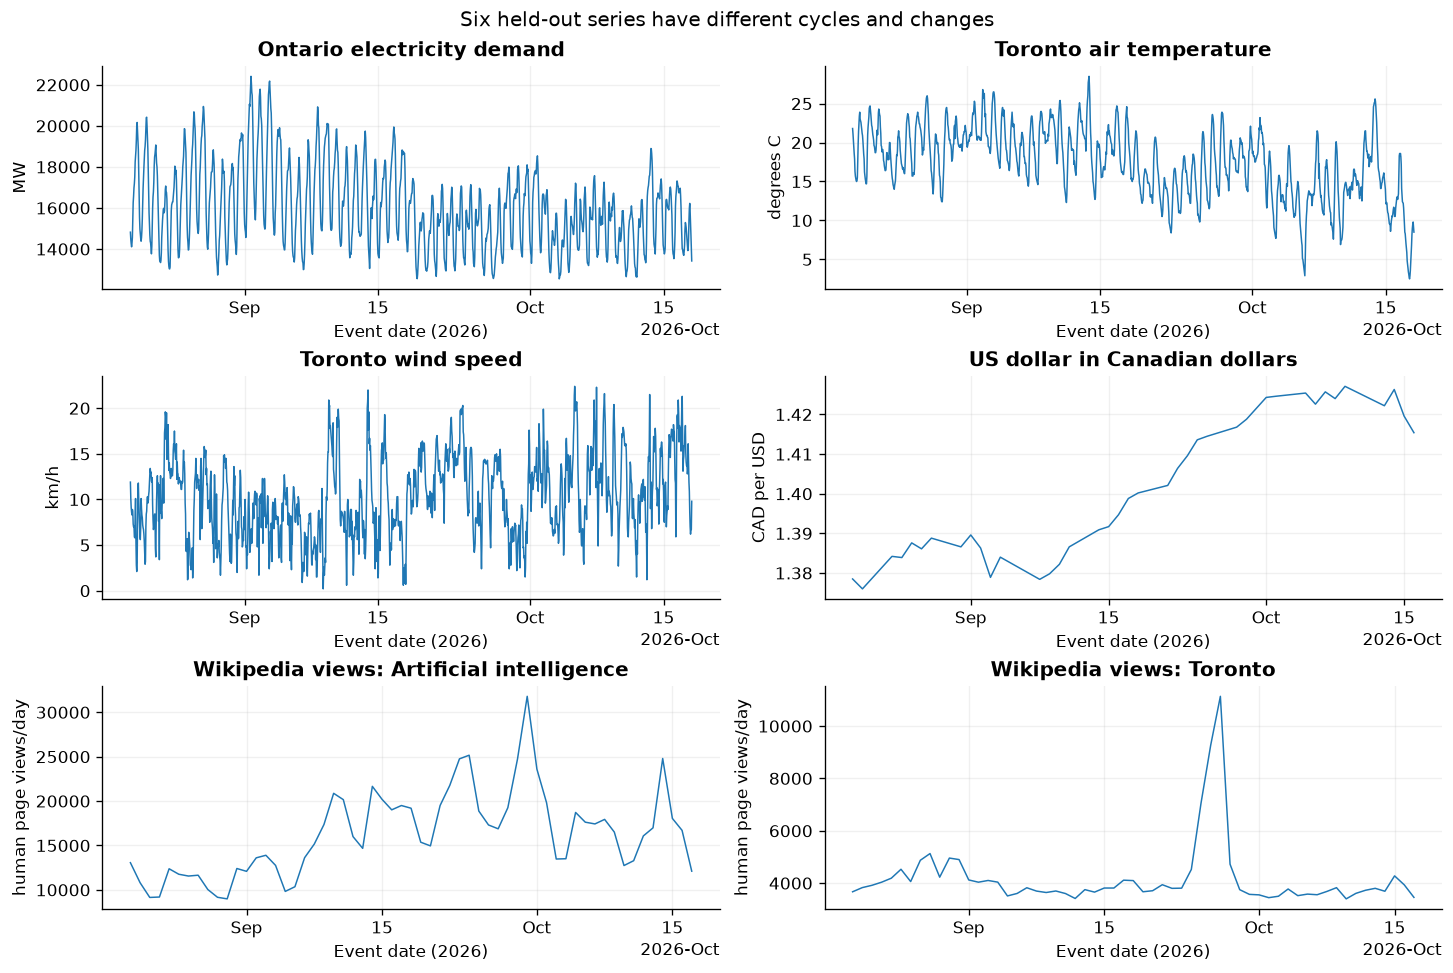

In [2]:
def normalize_frozen_sources():
    """Rebuild the normalized table from the six frozen public source files."""
    frames=[]
    def add(name,dates,values):
        frame=pd.DataFrame({'timestamp':pd.to_datetime(dates),'value':pd.to_numeric(values)})
        frame=frame.sort_values('timestamp').reset_index(drop=True)
        assert not frame.timestamp.duplicated().any() and np.isfinite(frame.value).all()
        frame['series']=name;frames.append(frame)
    demand=pd.read_csv(DATA/'raw/ieso_demand_2026.csv',skiprows=3)
    add('ontario_demand',pd.to_datetime(demand.Date)+pd.to_timedelta(demand.Hour-1,unit='h'),demand['Ontario Demand'])
    weather=read_json(DATA/'raw/toronto_weather.json')['hourly']
    for name,field in [('toronto_temperature','temperature_2m'),('toronto_wind','wind_speed_10m')]:
        add(name,weather['time'],weather[field])
    for name in ['wiki_toronto','wiki_ai']:
        items=read_json(DATA/'raw'/f'{name}.json')['items']
        add(name,pd.to_datetime([v['timestamp'][:8] for v in items],format='%Y%m%d'),[v['views'] for v in items])
    observed=[v for v in read_json(DATA/'raw/usd_cad.json')['observations'] if v.get('FXUSDCAD',{}).get('v') is not None]
    add('usd_cad',[v['d'] for v in observed],[v['FXUSDCAD']['v'] for v in observed])
    return pd.concat(frames,ignore_index=True)

manifest = read_json(DATA/'data_manifest.json')
series_meta = {s['id']:s for s in manifest['series']}
raw = pd.read_csv(DATA/'series.csv',parse_dates=['timestamp'])
assert hashlib.sha256((DATA/'series.csv').read_bytes()).hexdigest() == manifest['normalized_series_sha256']
for source in manifest['sources']:
    assert hashlib.sha256((DATA/source['file']).read_bytes()).hexdigest() == source['sha256']
assert not raw.duplicated(['series','timestamp']).any()
assert np.isfinite(raw.value).all()
pd.testing.assert_frame_equal(raw,normalize_frozen_sources(),check_dtype=False)
series = {name:g.sort_values('timestamp').reset_index(drop=True) for name,g in raw.groupby('series')}
for name,g in series.items():
    if series_meta[name]['frequency']=='h':
        assert g.timestamp.diff().dropna().eq(pd.Timedelta(hours=1)).all()
    elif name!='usd_cad':
        assert g.timestamp.diff().dropna().eq(pd.Timedelta(days=1)).all()
provenance = pd.DataFrame(read_json(DATA/'model_provenance.json'))
assert pd.to_datetime(provenance.availability_bound).max() < TARGET_START
print('Targets:',TARGET_START,'to',TARGET_END,'; values after this window are never scored.')
display(pd.DataFrame(manifest['series'])[['id','observations','data_start','data_end','unit','season_length']])
display(provenance[['name','model_id','availability_bound','license','hf_revision']])
display(raw.groupby('series').tail(2))
fig,axes=plt.subplots(3,2,figsize=(12,8),layout='constrained')
for ax,(name,g) in zip(axes.flat,series.items()):
    tail=g[g.timestamp.between(TARGET_START,TARGET_END)]
    ax.plot(tail.timestamp,tail.value,lw=.9)
    ax.set(title=series_meta[name]['label'],ylabel=series_meta[name]['unit'],xlabel='Event date (2026)')
    locator=mdates.AutoDateLocator(minticks=3,maxticks=5)
    ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle('Six held-out series have different cycles and changes')
fig.savefig(FIGURES/'inputs.png');plt.show()

The input chart shows the held-out values, not values sent to a model at once. Each forecast receives only the observations strictly before its origin. No scaling, clipping, missing-value imputation or weather covariates are added.

## 3. Rolling forecasts and baselines

At a rolling origin we freeze a history, ask for its next observations, then move the origin forward. We choose up to 20 evenly spaced eligible origins without consulting target values. Hourly models return 168 steps and are scored at the 24-step prefix and full 168 steps. Daily models return 28 steps and are scored at 7 and 28. A prefix need not equal a separately requested short forecast.

All seven families are compared at 512 observations. Five also support the 2,048-observation condition. TTM R3 and Lag-Llama are omitted from that condition because the catalog caps them at 512 and 1,024. The service does not expose immutable revision selection; public Hugging Face revisions are provenance references, not proof of the served weights. TimesFM 3 is newer but absent from this catalog snapshot. Moirai 2 and TTM R3 have noncommercial licences; this is noncommercial research and redistributes no weights.

```mermaid
flowchart LR
    A[One origin and one series<br/>512 or 2048 past observations] --> Q[Independent single-input requests<br/>up to 8 per batch, parallel HTTP queues]
    Q --> CH[Chronos-2<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    Q --> TF[TimesFM 2.5<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    Q --> MO[Moirai 2<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    Q --> TR[TiRex-2<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    Q --> TO[Toto 2<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    Q -->|512 only| TT[TTM R3<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    Q -->|512 only| LL[Lag-Llama<br/>TSFM.ai HTTP<br/>median and 9 quantiles]
    CH --> C[Wait for batch<br/>cache full requests and responses]
    TF --> C
    MO --> C
    TR --> C
    TO --> C
    TT --> C
    LL --> C
    C --> P[Score two horizon prefixes<br/>no automatic retries or fallbacks]
```

Each origin is a separate request inside the documented batch route, so later-origin histories are never additional inputs to an earlier forecast request. The default collector uses at most three concurrent batch HTTP calls. This collection also used separate daily and manual recovery queues. The run manifest derives peak HTTP concurrency from cached request times. A persisted intent prevents an uncertain interrupted call from being retried silently. Both successes and failures are cached; replay never contacts an endpoint.

In [3]:
cases=[]
for name,g in series.items():
    hourly=series_meta[name]['frequency']=='h'
    horizon=168 if hourly else 28
    eligible=[i for i in range(max(CONTEXTS),len(g)-horizon+1)
              if g.timestamp.iloc[i]>=TARGET_START and g.timestamp.iloc[i+horizon-1]<=TARGET_END]
    indices=np.unique(np.rint(np.linspace(0,len(eligible)-1,min(N_ORIGINS,len(eligible)))).astype(int))
    assert len(indices)>0
    for index in indices:
        i=eligible[index]
        for context in CONTEXTS:
            y=g.value.iloc[i-context:i].to_numpy(dtype=float)
            target=g.value.iloc[i:i+horizon].to_numpy(dtype=float)
            case={'id':f'{name}_{i}_{context}','series':name,'origin_index':i,
                  'origin':g.timestamp.iloc[i].isoformat(),'context':context,'horizon':horizon,
                  'season_length':series_meta[name]['season_length'],'frequency':'h' if hourly else 'D',
                  'history':y.tolist(),'actual':target.tolist(),
                  'target_dates':[v.isoformat() for v in g.timestamp.iloc[i:i+horizon]]}
            assert g.timestamp.iloc[i-1]<g.timestamp.iloc[i]
            cases.append(case)
plan=pd.DataFrame([{k:v for k,v in c.items() if k not in ['history','actual','target_dates']} for c in cases])
write_csv(plan,DATA/'origins.csv')
target_dates=pd.DataFrame([{'series':c['series'],'event_date':date,'value':value}
    for c in cases for date,value in zip(c['target_dates'],c['actual'])]).drop_duplicates(['series','event_date'])
assert pd.to_datetime(target_dates.event_date).between(TARGET_START,TARGET_END).all()
assert pd.to_datetime(target_dates.event_date).min()>pd.to_datetime(provenance.availability_bound).max()
write_csv(target_dates,DATA/'target_dates.csv')

def forecast_request(name,case):
    return {'model':MODELS[name][0],
            'inputs':[{'target':[[float(v)] for v in case['history']], 'metadata':{'item_id':case['id']}}],
            'parameters':{'prediction_length':case['horizon'],'frequency':case['frequency'],
                          'context_length':case['context'],'quantile_levels':QUANTILES.tolist()},
            'metadata':{'protocol':PROTOCOL}}
requests_plan=[(name,c,forecast_request(name,c)) for c in cases for name,(model,cap) in MODELS.items() if c['context']<=cap]
print('Origins per series:',plan.groupby('series').origin.nunique().to_dict())
print('Distinct target observations:',len(target_dates))
print('Hosted forecasts:',len(requests_plan),'baseline fits:',len(cases)*len(BASELINES),
      'published-price estimate: $',round(len(requests_plan)*RATE_USD,4))
print('Example request (history abbreviated for display only):')
example=json.loads(canonical(requests_plan[0][2]));example['inputs'][0]['target']=example['inputs'][0]['target'][:3]+[['... history continues ...']]
display(example)

Origins per series: {'ontario_demand': 20, 'toronto_temperature': 20, 'toronto_wind': 20, 'usd_cad': 12, 'wiki_ai': 20, 'wiki_toronto': 20}
Distinct target observations: 4405
Hosted forecasts: 1344 baseline fits: 1120 published-price estimate: $ 0.336
Example request (history abbreviated for display only):


{'inputs': [{'metadata': {'item_id': 'ontario_demand_5544_512'},
   'target': [[20893.0],
    [21029.0],
    [20816.0],
    ['... history continues ...']]}],
 'metadata': {'protocol': 'ts16-univariate-v1'},
 'model': 'amazon/chronos-2',
 'parameters': {'context_length': 512,
  'frequency': 'h',
  'prediction_length': 168,
  'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]}}

In [4]:
def hosted_path(request):
    return DATA/'cache_hosted'/f'{digest(request)}.json'

def existing_probe_count():
    count=0
    for path in (DATA/'probes').glob('*.json'):
        rec=read_json(path)
        count+=len(rec['request'].get('requests',[rec['request']]))
    return count

def collect_batch(requests_chunk):
    payload={'requests':requests_chunk}
    key=digest(payload)
    batch_path=DATA/'batches'/f'{key}.json'
    intent=DATA/'intents'/f'{key}.json'
    if batch_path.exists():
        record=read_json(batch_path)
    else:
        if not LIVE: raise RuntimeError('Offline cache miss; opt in with TS16_LIVE=1')
        if intent.exists(): raise RuntimeError(f'Unresolved forecast intent {key}; inspect billing before retrying')
        secret=credential()
        # Exclusive creation prevents two collectors from submitting the same batch.
        with intent.open('x',encoding='utf-8') as journal:
            json.dump({'endpoint':'/v1/forecast/batch','request_sha256':key,'request':payload,
                'forecast_requests':len(requests_chunk),'created_at':datetime.now(timezone.utc).isoformat()},journal)
        start=time.perf_counter()
        try:
            response=requests.post('https://api.tsfm.ai/v1/forecast/batch',
                    headers={'Authorization':'Bearer '+secret},json=payload,timeout=900)
            try: body=response.json()
            except ValueError: body={'error':'non-JSON response','text':response.text[:1000].replace(secret,'[redacted]')}
            status=response.status_code
        except requests.RequestException as error:
            body={'exception_type':type(error).__name__};status=None
        record={'request':payload,'request_sha256':key,'http_status':status,'response':body,
                'wall_seconds':time.perf_counter()-start,'collected_at':datetime.now(timezone.utc).isoformat(),
                'endpoint':'/v1/forecast/batch','forecast_requests':len(requests_chunk)}
        write_json(batch_path,record)
    data=record['response'].get('data',[])
    for idx,request in enumerate(requests_chunk):
        item=data[idx] if idx<len(data) else {'ok':False,'error':record['response']}
        previous=read_json(hosted_path(request)) if hosted_path(request).exists() else {}
        previous_batches=previous.get('previous_batches',[])
        if previous.get('batch_sha256') and previous['batch_sha256']!=key:
            previous_batches=previous_batches+[previous['batch_sha256']]
        write_json(hosted_path(request),{'request':request,'request_sha256':digest(request),
            'ok':item.get('ok',False),'response':item.get('result') or item.get('error'),
            'batch_sha256':key,'batch_http_status':record['http_status'],
            'previous_batches':previous_batches,
            'batch_wall_seconds':record['wall_seconds'],'collected_at':record.get('collected_at')})
    return {'batch':key[:10],'requests':len(requests_chunk),'http_status':record['http_status'],
            'seconds':round(record['wall_seconds'],2),'successful':sum(x.get('ok',False) for x in data)}

missing=[r for _,_,r in requests_plan if not hosted_path(r).exists()]
if missing and not LIVE: raise RuntimeError(f'Offline cache miss: {len(missing)} hosted requests; no API call made')
committed=sum(read_json(p)['forecast_requests'] for p in (DATA/'intents').glob('*.json'))+existing_probe_count()
assert (committed+len(missing))*RATE_USD<=MAX_COST_USD, 'Forecast budget exceeded'
chunks=[missing[i:i+BATCH_SIZE] for i in range(0,len(missing),BATCH_SIZE)]
with ThreadPoolExecutor(max_workers=HTTP_WORKERS) as pool:
    for future in as_completed([pool.submit(collect_batch,chunk) for chunk in chunks]):
        print(future.result(),flush=True)
print('Hosted responses available:',len(requests_plan))

def recover_failed_requests(batch_size=4):
    """Manual live recovery only, after reconciling recorded attempts with account usage."""
    if not LIVE: raise RuntimeError('Recovery requires explicit TS16_LIVE=1')
    failed=[r for _,_,r in requests_plan if not read_json(hosted_path(r))['ok']]
    attempted=sum(read_json(p)['forecast_requests'] for p in (DATA/'intents').glob('*.json'))+existing_probe_count()
    assert (attempted+len(failed))*RATE_USD<=MAX_COST_USD
    chunks=[failed[i:i+batch_size] for i in range(0,len(failed),batch_size)]
    if any((DATA/'batches'/f'{digest({"requests":c})}.json').exists() for c in chunks):
        raise RuntimeError('This recovery grouping is already cached; inspect it before choosing a smaller grouping')
    for chunk in chunks: print(collect_batch(chunk),flush=True)
    return len(failed)

Hosted responses available: 1344


The exact submitted history and returned JSON are saved under their full-request hashes. The excerpt below shows a raw response beside the parsed median. A requested 80% interval is the range between the 10th and 90th percentiles; over many matching cases it should contain about 80% of actual values. The API supplies nine quantiles for all seven families, including the TTM endpoint. We evaluate these hosted intervals without assuming how the provider constructed them.

In [5]:
def parse_hosted(record,case,name):
    if not record['ok']: raise ValueError('Hosted endpoint returned an error')
    body=record['response']
    assert body['model']==MODELS[name][0]
    assert not body.get('truncated_from'), 'Unexpected history truncation'
    assert body['input_points']==case['context'], 'Input count does not match the supplied history'
    assert len(body['outputs'])==1
    out=body['outputs'][0]
    assert out['metadata']['item_id']==case['id']
    h=case['horizon']
    mean=np.asarray(out['mean'],dtype=float)
    assert mean.shape==(h,1) and np.isfinite(mean).all()
    assert len(out['quantile_predictions'])==9
    assert all(np.asarray(q['values']).shape==(h,1) for q in out['quantile_predictions'])
    lookup={round(q['level'],3):np.asarray(q['values'],dtype=float)[:,0] for q in out['quantile_predictions']}
    qs=np.column_stack([lookup[round(q,3)] for q in QUANTILES])
    assert qs.shape==(h,9) and np.isfinite(qs).all()
    return {'point':qs[:,4].tolist(),'quantiles':qs.tolist(),
            'server_seconds':body.get('latency_ms',0)/1000,
            'quantile_crossing_fraction':float(np.mean(np.diff(qs,axis=1)<0))}

name,case,request=requests_plan[0]
record=read_json(hosted_path(request))
parsed=parse_hosted(record,case,name)
print('Full request and raw response:',str(hosted_path(request)))
display({k:record['response'].get(k) for k in ['id','model','provider','input_points','prediction_length','usage','latency_ms']})
first_raw=record['response']['outputs'][0]['quantile_predictions'][0]
display({'raw_first_quantile':{'level':first_raw['level'],'first_three_values':first_raw['values'][:3]},
         'parsed_first_three_medians':parsed['point'][:3]})

Full request and raw response: data\cache_hosted\f22de8095865ccaf36c20952a229a5ff9701dc10550a3e3a0b8dd6714249ef47.json


{'id': '2fce385b-dfba-4e21-8d8d-7ba0eea0c3c4',
 'model': 'amazon/chronos-2',
 'provider': 'harpoon',
 'input_points': 512,
 'prediction_length': 168,
 'usage': {'input_tokens': 1434, 'output_tokens': 1680, 'total_tokens': 3114},
 'latency_ms': 218}

{'raw_first_quantile': {'level': 0.1,
  'first_three_values': [[14665.181640625],
   [14159.998046875],
   [13735.634765625]]},
 'parsed_first_three_medians': [14916.65625, 14471.26953125, 14181.4609375]}

Five baselines receive the identical history. Seasonal naive repeats the latest seasonal cycle. AutoETS selects error and trend terms with additive seasonality. AutoARIMA searches a bounded set of seasonal autoregressive models (past values and past errors); its information criterion uses the history only. Theta extrapolates a smoothed trend with additive seasonal decomposition. Lag boosting fits small decision trees to past values and recursively predicts each new step. Its settings are fixed before scoring.

Seasonal naive uses Gaussian residual intervals with uncertainty increasing after each seasonal cycle. AutoETS, AutoARIMA and Theta return their fitted intervals; their native point forecast is used as an approximation to the median when assembling nine quantiles. This can introduce crossings for asymmetric fitted intervals, so their WQL includes that approximation. Lag boosting is point-only and has no interval score. There is no target-based model selection. Forecasts and local run times are cached as well. Long seasonal periods make the bounded ARIMA search an intentionally modest fitted baseline.

In [6]:
BASELINE_CONFIG={
    'Seasonal naive':{'interval':'seasonal-residual Gaussian, sqrt(1+floor(step/m))'},
    'AutoETS':{'model':'ZZA','distribution':'normal'},
    'AutoARIMA':{'max_p':2,'max_q':2,'max_P':1,'max_Q':1,'max_order':4,
                 'nmodels':20,'approximation':True,'stepwise':True,'seasonal':True},
    'Theta':{'decomposition_type':'additive'},
    'Lag boosting':{'max_iter':100,'max_leaf_nodes':15,'min_samples_leaf':10,
                    'early_stopping':False,'random_state':1601},
}

def baseline_request(name,case):
    return {'protocol':PROTOCOL,'name':name,'case_id':case['id'],'history':case['history'],
            'horizon':case['horizon'],'season_length':case['season_length'],
            'quantiles':QUANTILES.tolist(),'configuration':BASELINE_CONFIG[name],
            'versions':{k:VERSIONS[k] for k in ['numpy','scipy','statsforecast','scikit-learn']}}

def fitted_forecast(name,case):
    request=baseline_request(name,case);key=digest(request);path=DATA/'cache_baselines'/f'{key}.json'
    if path.exists(): return read_json(path)
    y=np.asarray(case['history'],dtype=float);h=case['horizon'];m=case['season_length'];start=time.perf_counter()
    try:
        if name=='Seasonal naive':
            point=np.resize(y[-m:],h)
            sigma=np.sqrt(np.mean((y[m:]-y[:-m])**2))
            scale=sigma*np.sqrt(1+np.arange(h)//m)
            qs=point[:,None]+scale[:,None]*norm.ppf(QUANTILES)[None,:]
        elif name=='Lag boosting':
            lags=sorted(set([1,2,3,m,2*m] + ([24,48,168] if case['frequency']=='h' else [7,14,21])))
            lags=[lag for lag in lags if lag<len(y)//2]
            X=np.array([[y[t-lag] for lag in lags] for t in range(max(lags),len(y))])
            target=y[max(lags):]
            with threadpool_limits(limits=1):
                model=HistGradientBoostingRegressor(**BASELINE_CONFIG[name]).fit(X,target)
                history=y.tolist();pred=[]
                for _ in range(h):
                    value=float(model.predict([[history[-lag] for lag in lags]])[0]);history.append(value);pred.append(value)
            point=np.asarray(pred);qs=None
        else:
            kwargs=BASELINE_CONFIG[name].copy()
            if name=='AutoETS':model=AutoETS(season_length=m,**kwargs)
            elif name=='AutoARIMA':model=AutoARIMA(season_length=m,**kwargs)
            else:model=Theta(season_length=m,**kwargs)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                result=model.forecast(y=y,h=h,level=[20,40,60,80])
            point=np.asarray(result['mean'],dtype=float)
            qs=np.column_stack([result[f'lo-{v}'] for v in [80,60,40,20]]+[point]+
                               [result[f'hi-{v}'] for v in [20,40,60,80]])
        assert point.shape==(h,) and np.isfinite(point).all()
        assert qs is None or (qs.shape==(h,9) and np.isfinite(qs).all())
        record={'request':request,'request_sha256':key,'ok':True,'point':point.tolist(),
                'quantiles':None if qs is None else qs.tolist(),'wall_seconds':time.perf_counter()-start,
                'warnings':[str(w.message) for w in caught] if name in ['AutoETS','AutoARIMA','Theta'] else []}
    except Exception as error:
        record={'request':request,'request_sha256':key,'ok':False,'error_type':type(error).__name__,
                'error':str(error),'wall_seconds':time.perf_counter()-start}
    write_json(path,record);return record

# Sequential fits avoid thread-limit interference; native routines run on this machine.
for i,case in enumerate(cases):
    for name in BASELINES: fitted_forecast(name,case)
    if (i+1)%20==0: print('Baseline histories complete:',i+1,'/',len(cases),flush=True)

Baseline histories complete: 20 / 224


Baseline histories complete: 40 / 224


Baseline histories complete: 60 / 224


Baseline histories complete:

 80 / 224


...

Baseline histories complete: 140 / 224


Baseline histories complete: 160 / 224


Baseline histories complete: 180 / 224


Baseline histories complete: 200 / 224


Baseline histories complete: 220 / 224


## 4. Point forecast results

Mean absolute error (MAE) is the average size of an error in the series' units. Mean absolute scaled error (MASE) divides MAE by the history's mean seasonal difference; it does not use the test errors as its scale. Weighted absolute percentage error (WAPE) divides the sum of absolute errors by the sum of absolute actual values, so its interpretation is limited for temperature near zero.

For comparisons across units, relative MAE divides a method's held-out absolute error by seasonal naive's held-out error for the same series, origins, context and horizon. A value of 0.8 means 20% less error. We sum errors within each series before taking that ratio and then give each series equal weight. The two horizons receive equal weight. Overlapping origins are not independent observations. Confidence intervals resample the six whole series, not individual forecast steps.

Successful model-origin conditions: 2464 failures: 0


,model,context,mean_mase,mean_wape
4,Chronos-2,512,1.3844,0.1482
9,Moirai 2,512,1.3891,0.1495
20,Toto 2,512,1.4110,0.1512
16,TiRex-2,512,1.4268,0.1520
2,AutoETS,512,1.4660,0.1629
18,TimesFM 2.5,512,1.4844,0.1527
11,Seasonal naive,512,1.5216,0.1755
0,AutoARIMA,512,1.5725,0.1728
14,Theta,512,1.5742,0.1792
6,Lag boosting,512,1.7275,0.1884


,model,context,relative_mae,skill_percent,ci_low,ci_high,series
4,Chronos-2,512,0.860,14.043,0.748,0.974,6
9,Moirai 2,512,0.862,13.781,0.750,0.977,6
16,TiRex-2,512,0.869,13.075,0.740,1.026,6
20,Toto 2,512,0.871,12.876,0.756,0.992,6
18,TimesFM 2.5,512,0.911,8.928,0.768,1.070,6
2,AutoETS,512,0.961,3.936,0.909,1.014,6
11,Seasonal naive,512,1.000,0.000,1.000,1.000,6
0,AutoARIMA,512,1.002,-0.215,0.908,1.107,6
14,Theta,512,1.086,-8.627,0.899,1.379,6
6,Lag boosting,512,1.150,-15.050,1.046,1.254,6


{'best_hosted': 'Chronos-2',
 'best_baseline': 'AutoETS',
 'relative_mae_difference': -0.10107008021873554,
 'paired_series_bootstrap_95': [-0.23290562304372778, 0.015079188920463485],
 'selection_note': 'Both named winners were selected after evaluation; this is descriptive, not a corrected significance test.'}

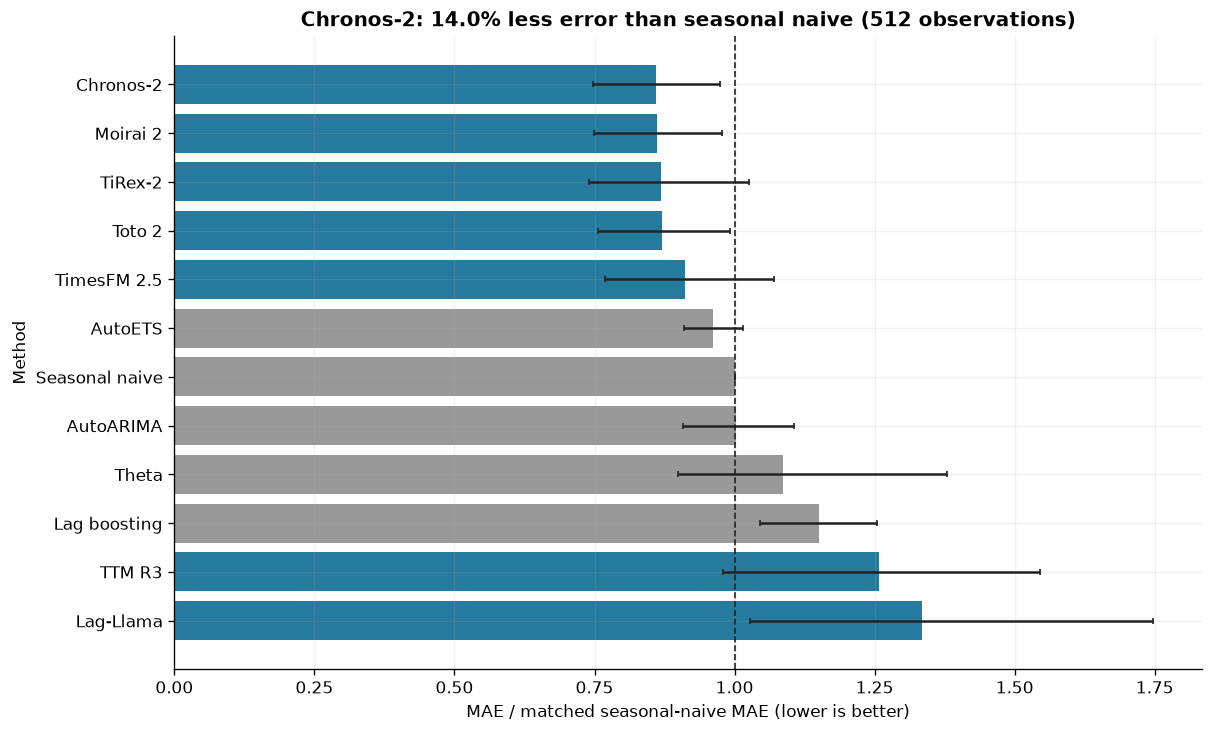

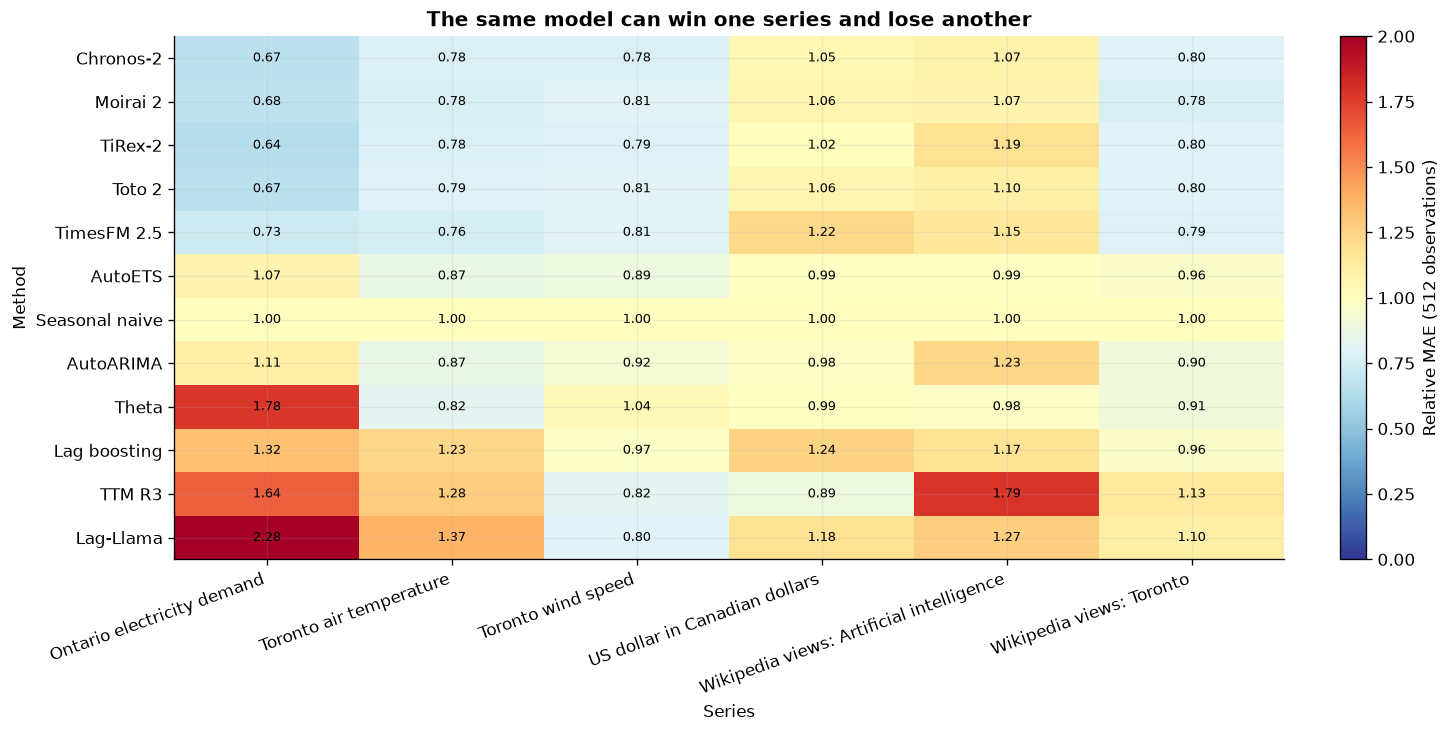

In [7]:
rows=[];failures=[];predictions={}
for case in cases:
    for name in list(MODELS)+BASELINES:
        if name in MODELS and case['context']>MODELS[name][1]: continue
        try:
            if name in MODELS:
                rec=read_json(hosted_path(forecast_request(name,case)))
                pred=parse_hosted(rec,case,name);seconds=pred['server_seconds']
            else:
                rec=fitted_forecast(name,case)
                if not rec['ok']:raise ValueError(rec.get('error','baseline failed'))
                pred=rec;seconds=rec['wall_seconds']
            predictions[(name,case['id'])]=pred
            y=np.asarray(case['actual']);point=np.asarray(pred['point'])
            hist=np.asarray(case['history']);m=case['season_length']
            scale=float(np.mean(np.abs(hist[m:]-hist[:-m])))
            for h in ([24,168] if case['frequency']=='h' else [7,28]):
                error=np.abs(point[:h]-y[:h]);den=float(np.abs(y[:h]).sum())
                row={'model':name,'series':case['series'],'case_id':case['id'],'origin':case['origin'],
                     'context':case['context'],'horizon':h,'horizon_kind':'short' if h in [24,7] else 'long',
                     'mae':float(error.mean()),'mase':float(error.mean()/scale) if scale else None,
                     'abs_error_sum':float(error.sum()),'abs_actual_sum':den,'points':h,
                     'wape':float(error.sum()/den) if den else None,'seconds':seconds}
                if pred['quantiles'] is not None:
                    q=np.asarray(pred['quantiles'])[:h];diff=y[:h,None]-q
                    pinball=np.maximum(QUANTILES*diff,(QUANTILES-1)*diff)
                    row.update({'coverage80':float(np.mean((y[:h]>=q[:,0])&(y[:h]<=q[:,-1]))),
                                'width80':float(np.mean(q[:,-1]-q[:,0])),
                                'wql':float(2*pinball.sum()/9/den) if den else None,
                                'crossing_fraction':float(np.mean(np.diff(q,axis=1)<0))})
                rows.append(row)
        except Exception as error:
            failures.append({'model':name,'case_id':case['id'],'series':case['series'],
                             'context':case['context'],'error_type':type(error).__name__,'error':str(error)})
metrics=pd.DataFrame(rows);write_csv(metrics,DATA/'metrics.csv');write_json(DATA/'failures.json',failures)
print('Successful model-origin conditions:',len(predictions),'failures:',len(failures))
if failures:display(pd.DataFrame(failures).groupby(['model','error']).size().rename('count').reset_index())
# Require complete matched origins before making aggregate comparisons.
counts=metrics.groupby(['model','context','series','horizon_kind']).size()
expected=plan.groupby(['context','series']).size()
for (name,context,s,h),n in counts.items():
    assert n==expected.loc[(context,s)], f'Incomplete comparisons: {name}, {s}, {context}, {h}'
agg=metrics.groupby(['model','context','series','horizon_kind'],as_index=False).agg(
    abs_error_sum=('abs_error_sum','sum'),abs_actual_sum=('abs_actual_sum','sum'),
    mase=('mase','mean'),coverage80=('coverage80','mean'),wql=('wql','mean'),
    width80=('width80','mean'),crossing_fraction=('crossing_fraction','mean'),origins=('origin','nunique'))
reference=agg[agg.model=='Seasonal naive'][['context','series','horizon_kind','abs_error_sum']].rename(columns={'abs_error_sum':'naive_error_sum'})
agg=agg.merge(reference,on=['context','series','horizon_kind'],validate='many_to_one')
assert (agg.naive_error_sum>0).all()
agg['relative_mae']=agg.abs_error_sum/agg.naive_error_sum
agg['wape']=agg.abs_error_sum/agg.abs_actual_sum
write_csv(agg,DATA/'series_scores.csv')
point_metrics=agg.groupby(['model','context'],as_index=False).agg(mean_mase=('mase','mean'),mean_wape=('wape','mean'))
write_csv(point_metrics,DATA/'point_metrics.csv');display(point_metrics.sort_values(['context','mean_mase']).round(4))
series_scores=agg.groupby(['model','context','series'],as_index=False).relative_mae.mean()
rng=np.random.default_rng(1601);summary=[]
for (name,context),g in series_scores.groupby(['model','context']):
    values=g.relative_mae.to_numpy();boot=rng.choice(values,(10000,len(values)),replace=True).mean(axis=1)
    summary.append({'model':name,'context':context,'relative_mae':float(values.mean()),
                    'skill_percent':float(100*(1-values.mean())),
                    'ci_low':float(np.quantile(boot,.025)),'ci_high':float(np.quantile(boot,.975)),
                    'series':len(values)})
summary=pd.DataFrame(summary).sort_values(['context','relative_mae']);write_csv(summary,DATA/'summary.csv')
display(summary.round(3))
best_host_name=summary[(summary.context==512)&summary.model.isin(MODELS)].iloc[0].model
best_base_name=summary[(summary.context==512)&summary.model.isin(BASELINES)].iloc[0].model
compare=series_scores[series_scores.context==512].pivot(index='series',columns='model',values='relative_mae')
differences=(compare[best_host_name]-compare[best_base_name]).to_numpy()
paired_boot=np.random.default_rng(1602).choice(differences,(10000,len(differences)),replace=True).mean(axis=1)
comparison={'best_hosted':best_host_name,'best_baseline':best_base_name,
    'relative_mae_difference':float(differences.mean()),
    'paired_series_bootstrap_95':np.quantile(paired_boot,[.025,.975]).tolist(),
    'selection_note':'Both named winners were selected after evaluation; this is descriptive, not a corrected significance test.'}
write_json(DATA/'paired_comparison.json',comparison);display(comparison)
fig,ax=plt.subplots(figsize=(10,6),layout='constrained')
g=summary[summary.context==512].sort_values('relative_mae',ascending=False)
ax.barh(g.model,g.relative_mae,color=['#257a9d' if x in MODELS else '#999999' for x in g.model])
ax.errorbar(g.relative_mae,g.model,xerr=[g.relative_mae-g.ci_low,g.ci_high-g.relative_mae],fmt='none',ecolor='#222',capsize=2)
ax.axvline(1,color='#222',ls='--',lw=1)
ax.set(xlabel='MAE / matched seasonal-naive MAE (lower is better)',ylabel='Method',
       title='Chronos-2: 14.0% less error than seasonal naive (512 observations)')
fig.savefig(FIGURES/'headline.png');plt.show()
fig,ax=plt.subplots(figsize=(12,6),layout='constrained')
heat=series_scores[series_scores.context==512].pivot(index='model',columns='series',values='relative_mae')
heat=heat.loc[g.model.iloc[::-1]]
im=ax.imshow(heat,aspect='auto',cmap='RdYlBu_r',vmin=0,vmax=max(2,float(np.nanpercentile(heat,95))))
ax.set_xticks(range(len(heat.columns)),[series_meta[c]['label'] for c in heat.columns],rotation=20,ha='right')
ax.set_yticks(range(len(heat)),heat.index)
for i in range(len(heat)):
    for j in range(len(heat.columns)):ax.text(j,i,f'{heat.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
ax.set(title='The same model can win one series and lose another',xlabel='Series',ylabel='Method')
fig.colorbar(im,ax=ax,label='Relative MAE (512 observations)')
fig.savefig(FIGURES/'by_series.png');plt.show()

At 512 observations, Chronos-2 had **0.860 relative MAE**, versus 0.961 for AutoETS. Its series-resampling interval was 0.748 to 0.974. The paired difference from the best baseline was -0.101, with a descriptive 95% interval of -0.233 to 0.015. Both winners were selected after evaluation; the interval does not correct for that selection or make these six series representative.

The heatmap gives each series separately. A value above 1 means that method lost to repeating the seasonal cycle for that series, averaged equally over the two horizons.

## 5. Intervals and calibration

Coverage is the fraction of actual values inside the reported 80% interval. Coverage alone rewards intervals that are too wide, so we also score all nine quantiles. Weighted quantile loss (WQL) penalizes both missed values and overly wide predictions, normalized by the sum of absolute actual values. This nine-quantile approximation is not the full continuous ranked probability score. Scores are averaged within a series and then across series; the weather normalization caveat still applies. Crossed quantiles are reported, never sorted or repaired. The crossing fraction counts decreasing adjacent quantile pairs; the error analysis separately counts forecast steps with any crossing.

,model,coverage80,wql,crossing_fraction
2,Chronos-2,0.6744,0.1202,0.0000
5,Moirai 2,0.6549,0.1221,0.0000
11,Toto 2,0.7010,0.1223,0.0000
9,TiRex-2,0.6829,0.1230,0.0000
10,TimesFM 2.5,0.2097,0.1345,0.1250
1,AutoETS,0.7106,0.1373,0.0000
0,AutoARIMA,0.7321,0.1452,0.0000
6,Seasonal naive,0.8157,0.1508,0.0000
4,Lag-Llama,0.7814,0.1626,0.0000
7,TTM R3,0.5473,0.1758,0.0000


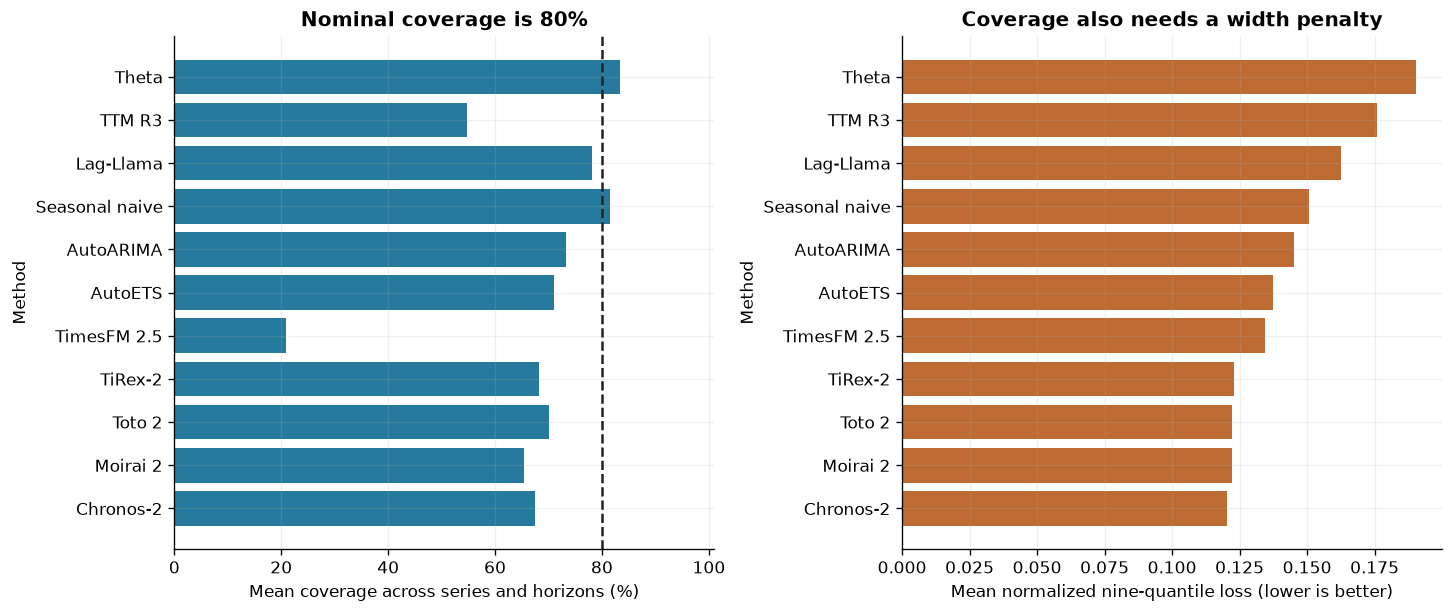

In [8]:
intervals=agg[agg.context==512].groupby('model',as_index=False).agg(
    coverage80=('coverage80','mean'),wql=('wql','mean'),crossing_fraction=('crossing_fraction','mean'))
intervals=intervals.dropna(subset=['coverage80']).sort_values('wql')
write_csv(intervals,DATA/'interval_summary.csv');display(intervals.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
axes[0].barh(intervals.model,intervals.coverage80*100,color='#257a9d')
axes[0].axvline(80,color='#222',ls='--');axes[0].set(xlim=(0,101),xlabel='Mean coverage across series and horizons (%)',title='Nominal coverage is 80%',ylabel='Method')
axes[1].barh(intervals.model,intervals.wql,color='#bd6b33')
axes[1].set(xlabel='Mean normalized nine-quantile loss (lower is better)',title='Coverage also needs a width penalty',ylabel='Method')
fig.savefig(FIGURES/'intervals.png');plt.show()

Chronos-2's 80% interval covered **67.4%** of targets in the equal-series, equal-horizon average. Across interval-producing methods, coverage ranged from 21.0% to 83.4%. The raw nine-quantile outputs and any crossings remain in the caches; no interval was widened after seeing these targets.

## 6. Context, latency and spend

A longer history is a paired comparison over the same origins and horizons. We compare only families that support both lengths. Hosted server latency and batch wall time are recorded separately. Batch wall time includes network overhead and concurrent execution and cannot be assigned to an individual model. Local baselines run on different hardware, so their seconds are operational measurements, not a controlled speed contest.

context,512,2048,change_2048_minus_512
model,,,
AutoARIMA,1.002,0.954,-0.048
AutoETS,0.961,0.900,-0.061
Chronos-2,0.860,0.844,-0.015
Lag boosting,1.150,1.304,0.154
Moirai 2,0.862,0.815,-0.047
Seasonal naive,1.000,1.000,0.000
Theta,1.086,0.932,-0.155
TiRex-2,0.869,0.835,-0.034
TimesFM 2.5,0.911,0.869,-0.042


,model,median_seconds,p95_seconds,forecasts
0,AutoARIMA,0.419,21.655,224
1,AutoETS,0.570,6.765,224
2,Chronos-2,0.036,0.038,224
3,Lag boosting,0.161,0.316,224
4,Lag-Llama,21.912,22.078,112
5,Moirai 2,0.046,0.079,224
6,Seasonal naive,0.000,0.001,224
7,TTM R3,0.043,0.047,112
8,Theta,0.049,0.227,224
9,TiRex-2,0.029,0.033,224


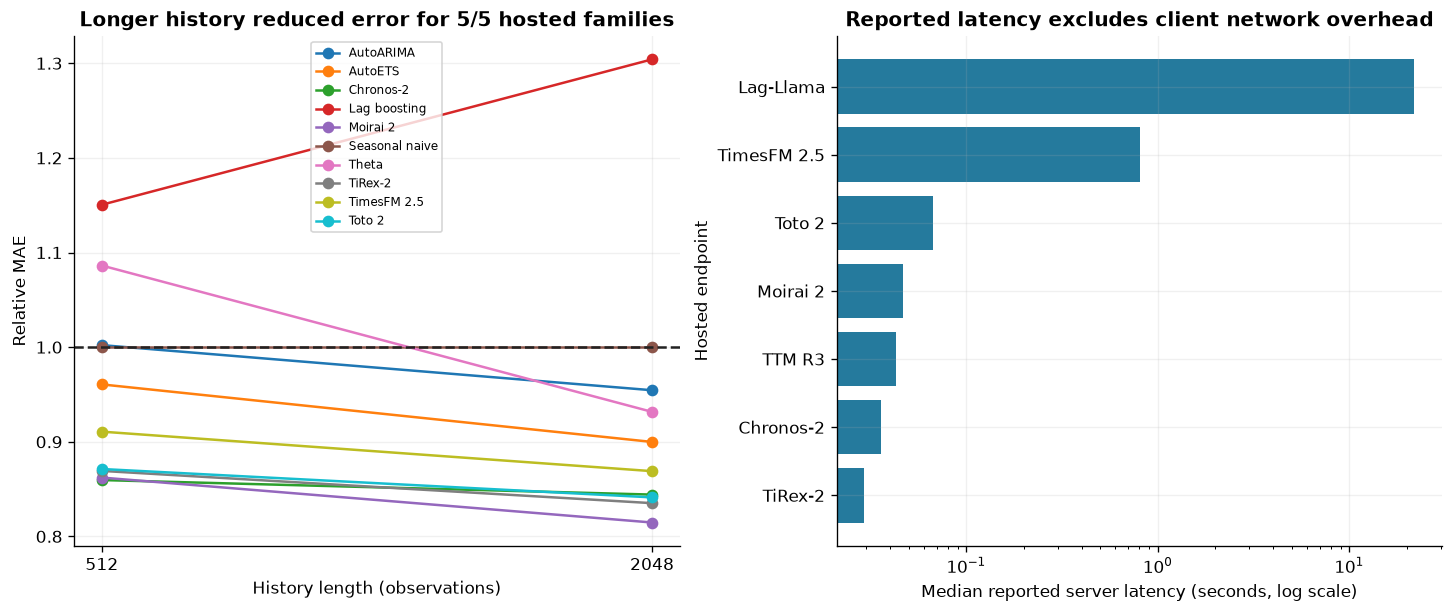

{'published_usd_per_forecast': 0.00025,
 'experiment_forecast_requests': 1344,
 'experiment_request_attempts': 1368,
 'additional_request_attempts': 24,
 'probe_forecast_requests': 9,
 'batch_http_calls': 177,
 'batch_transport_failures': 3,
 'published_price_estimate_usd': 0.34425,
 'cache_failures': 0,
 'cash_payment_usd': None,
 'note': 'Account usage deltas, when present, are authoritative. No top-up or subscription was activated.',
 'baseline_fit_predict_wall_seconds_sum': 1147.9177434999874,
 'account_credits_consumed': 1377,
 'account_usage_cost_delta_usd': 0.34425}

In [9]:
paired=summary.pivot(index='model',columns='context',values='relative_mae').dropna()
paired['change_2048_minus_512']=paired[2048]-paired[512]
write_csv(paired.reset_index(),DATA/'context_comparison.csv');display(paired.round(3))
latency=metrics.drop_duplicates(['model','case_id']).groupby('model',as_index=False).agg(
    median_seconds=('seconds','median'),p95_seconds=('seconds',lambda x:x.quantile(.95)),forecasts=('case_id','count'))
write_csv(latency,DATA/'latency.csv');display(latency.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for name,row in paired.iterrows():axes[0].plot([512,2048],[row[512],row[2048]],marker='o',label=name)
axes[0].axhline(1,color='#222',ls='--');axes[0].set(xticks=CONTEXTS,xlabel='History length (observations)',ylabel='Relative MAE',title='Longer history reduced error for 5/5 hosted families')
axes[0].legend(fontsize=7)
host_latency=latency[latency.model.isin(MODELS)].sort_values('median_seconds')
axes[1].barh(host_latency.model,host_latency.median_seconds,color='#257a9d')
axes[1].set_xscale('log')
axes[1].set(xlabel='Median reported server latency (seconds, log scale)',ylabel='Hosted endpoint',title='Reported latency excludes client network overhead')
fig.savefig(FIGURES/'context_latency.png');plt.show()
batch_records=[read_json(p) for p in (DATA/'batches').glob('*.json')]
events=[]
for record in batch_records:
    end=pd.Timestamp(record['collected_at'])
    events.extend([(end-pd.Timedelta(seconds=record['wall_seconds']),1),(end,-1)])
active=0;collection_peak_batches=0
for _,change in sorted(events):
    active+=change;collection_peak_batches=max(collection_peak_batches,active)
probe_requests=existing_probe_count()
attempted_requests=sum(len(r['request']['requests']) for r in batch_records)
spend={'published_usd_per_forecast':RATE_USD,'experiment_forecast_requests':len(requests_plan),
       'experiment_request_attempts':attempted_requests,
       'additional_request_attempts':attempted_requests-len(requests_plan),
       'probe_forecast_requests':probe_requests,'batch_http_calls':len(batch_records),
       'batch_transport_failures':sum(r['http_status']!=200 for r in batch_records),
       'published_price_estimate_usd':(attempted_requests+probe_requests)*RATE_USD,
       'cache_failures':len(failures),'cash_payment_usd':None,
       'note':'Account usage deltas, when present, are authoritative. No top-up or subscription was activated.',
       'baseline_fit_predict_wall_seconds_sum':float(metrics.drop_duplicates(['model','case_id']).query('model in @BASELINES').seconds.sum())}
if (DATA/'billing_after_collection.json').exists():
    before=read_json(DATA/'billing_before.json');after=read_json(DATA/'billing_after_collection.json')
    spend.update({'account_credits_consumed':before['credits_remaining']-after['credits_remaining'],
                  'account_usage_cost_delta_usd':after['usage_cost_usd']-before['usage_cost_usd']})
write_json(DATA/'spend.json',spend);display(spend)

Longer history reduced relative MAE for **5/5** hosted families that support both lengths. At 2,048 observations, Moirai 2 had the lowest hosted relative MAE (0.815). The unsupported TTM R3 and Lag-Llama conditions are absent rather than silently truncated.

Collection made 1368 experiment request attempts for 1,344 unique forecasts, plus 9 probe requests. The 24 additional attempts are recorded with their failed batch envelopes. Account usage increased by $0.34425; the published-price attempt estimate is $0.34425. No top-up or subscription was activated. The account reports usage cost; this is not a paid-invoice confirmation.

## 7. Error analysis

We select the largest relative error among the best hosted model's long-horizon origin conditions after scoring. This is a diagnostic example, not a second test set. The plot shows the recent input, all target values and the endpoint's interval; it can reveal a missed level change or an interval that fails to widen.

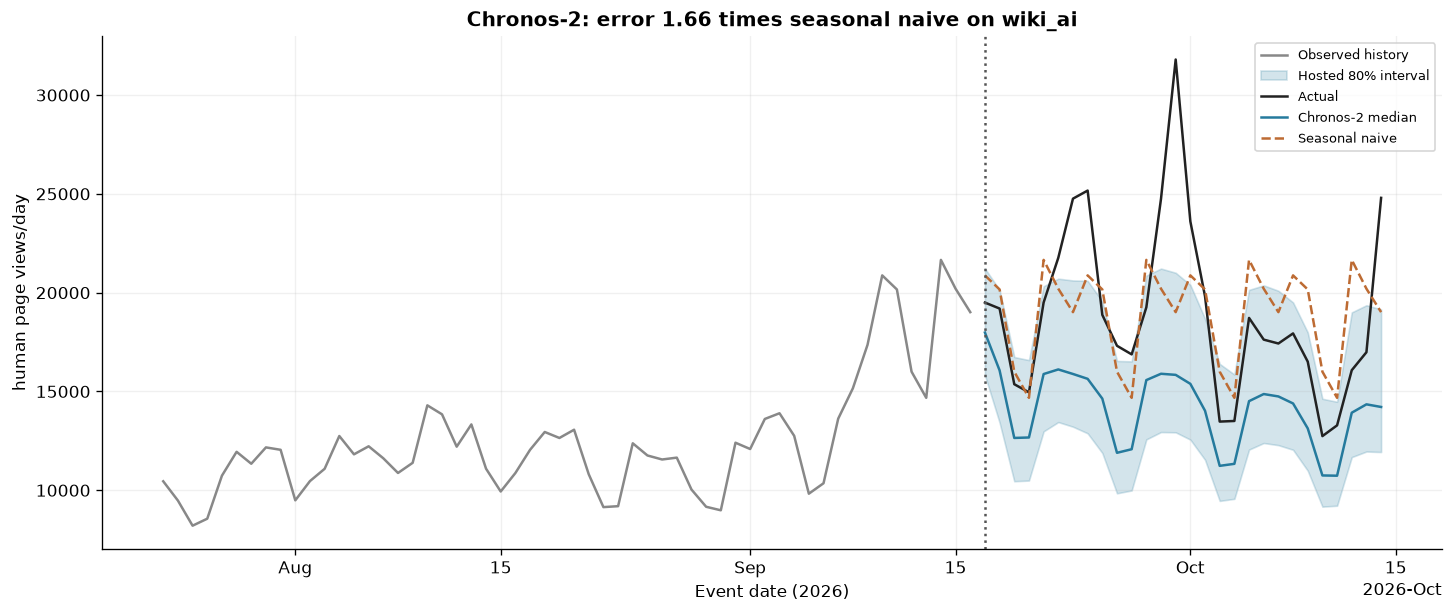

,value
model,Chronos-2
series,wiki_ai
origin,2026-09-17T00:00:00
mae,4827.626674
naive_mae,2901.607143
relative_mae,1.663777


In [10]:
best_host=summary[(summary.context==512)&summary.model.isin(MODELS)].iloc[0]['model']
worst=metrics[(metrics.model==best_host)&(metrics.context==512)&(metrics.horizon_kind=='long')].merge(
    metrics[(metrics.model=='Seasonal naive')&(metrics.context==512)&(metrics.horizon_kind=='long')][['case_id','mae']].rename(columns={'mae':'naive_mae'}),on='case_id')
worst['relative_mae']=worst.mae/worst.naive_mae
error=worst.sort_values('relative_mae',ascending=False).iloc[0]
case=next(c for c in cases if c['id']==error.case_id);pred=predictions[(best_host,case['id'])]
g=series[case['series']];i=case['origin_index'];tail=min(case['context'],2*case['horizon'])
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.plot(g.timestamp.iloc[i-tail:i],g.value.iloc[i-tail:i],color='#888',label='Observed history')
dates=pd.to_datetime(case['target_dates']);q=np.asarray(pred['quantiles'])
ax.fill_between(dates,q[:,0],q[:,-1],alpha=.2,color='#257a9d',label='Hosted 80% interval')
ax.plot(dates,case['actual'],color='#222',lw=1.5,label='Actual')
ax.plot(dates,pred['point'],color='#257a9d',label=best_host+' median')
naive=predictions[('Seasonal naive',case['id'])]['point']
ax.plot(dates,naive,color='#bd6b33',ls='--',label='Seasonal naive')
ax.axvline(dates[0],color='#555',ls=':')
ax.set(title=f'{best_host}: error {error.relative_mae:.2f} times seasonal naive on {case["series"]}',
       xlabel='Event date (2026)',ylabel=series_meta[case['series']]['unit']);ax.legend(fontsize=8)
locator=mdates.AutoDateLocator(minticks=3,maxticks=6)
ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.savefig(FIGURES/'error_example.png');plt.show()
write_json(DATA/'error_example.json',{'model':best_host,'case_id':case['id'],'series':case['series'],
    'origin':case['origin'],'horizon':case['horizon'],'mae':float(error.mae),
    'seasonal_naive_mae':float(error.naive_mae),'relative_mae':float(error.relative_mae)})
display(error[['model','series','origin','mae','naive_mae','relative_mae']].to_frame('value'))

At the selected origin (2026-09-17T00:00:00), Chronos-2's 28-step forecast had MAE **4827.627**, versus 2901.607 for seasonal naive (1.66 times as much error). This is the worst origin ratio for the overall winning endpoint, selected after scoring; it illustrates that the average winner can still lose a specific forecast.

A quantile should increase as its probability increases: a 10th percentile above a 20th percentile is inconsistent. The next diagnostic checks the original maximum-horizon forecasts once each, across both context lengths, without counting the two scored prefixes twice. It displays one raw TimesFM quantile curve. We retain the provider's labels and do not infer or repair its internal channel mapping. Fitted baselines use their point forecast as the median approximation, so their crossings need that separate interpretation.

,model,steps,steps_with_crossing,crossed_adjacent_pairs,adjacent_pairs,crossed_steps_percent
0,AutoARIMA,23072,0,0,184576,0.000000
1,AutoETS,23072,0,0,184576,0.000000
2,Chronos-2,23072,0,0,184576,0.000000
3,Lag-Llama,11536,0,0,92288,0.000000
4,Moirai 2,23072,0,0,184576,0.000000
5,Seasonal naive,23072,0,0,184576,0.000000
6,TTM R3,11536,0,0,92288,0.000000
7,Theta,23072,36,36,184576,0.156033
8,TiRex-2,23072,0,0,184576,0.000000
9,TimesFM 2.5,23072,23072,23072,184576,100.000000


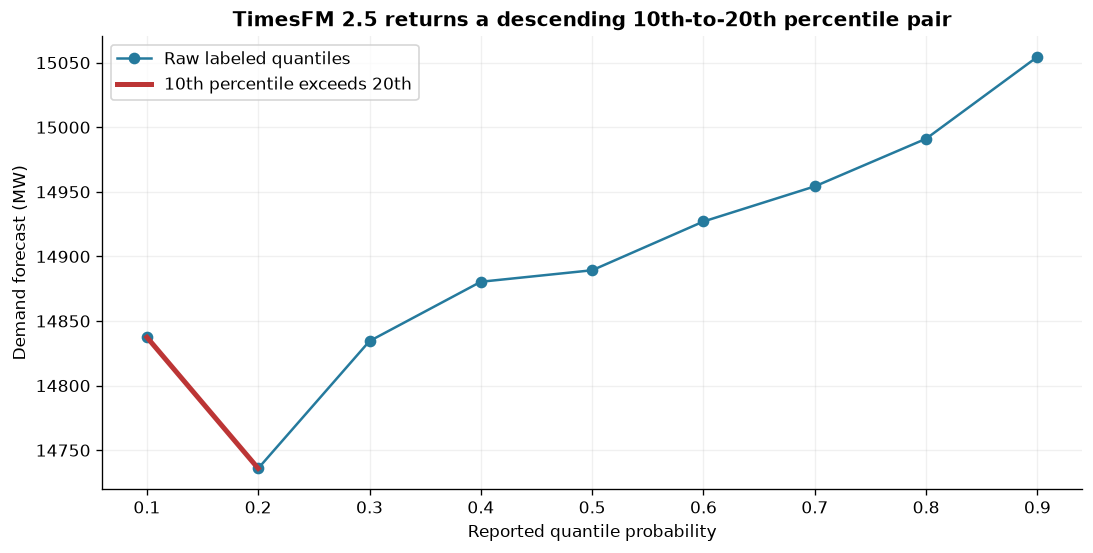

,reported_probability,raw_forecast
0,0.1,14837.468750
1,0.2,14735.902344
2,0.3,14834.469727
3,0.4,14880.388672
4,0.5,14889.292969
5,0.6,14927.050781
6,0.7,14954.244141
7,0.8,14991.136719
8,0.9,15054.548828


In [11]:
diagnostic_rows=[]
for (name,case_id),pred in predictions.items():
    if pred['quantiles'] is None:continue
    q=np.asarray(pred['quantiles']);crossed=np.diff(q,axis=1)<0
    diagnostic_rows.append({'model':name,'case_id':case_id,'steps':len(q),
        'steps_with_crossing':int(np.any(crossed,axis=1).sum()),
        'crossed_adjacent_pairs':int(crossed.sum()),'adjacent_pairs':int(crossed.size)})
diagnostics=pd.DataFrame(diagnostic_rows).groupby('model',as_index=False).sum(numeric_only=True)
diagnostics['crossed_steps_percent']=100*diagnostics.steps_with_crossing/diagnostics.steps
write_csv(diagnostics,DATA/'quantile_diagnostics.csv');display(diagnostics)
example_case=next(c for c in cases if c['series']=='ontario_demand' and c['context']==512)
q=np.asarray(predictions[('TimesFM 2.5',example_case['id'])]['quantiles'])[0]
raw_record=read_json(hosted_path(forecast_request('TimesFM 2.5',example_case)))
anomaly={'model':'TimesFM 2.5','case_id':example_case['id'],'forecast_step':1,
    'origin':example_case['origin'],'quantile_levels':QUANTILES.tolist(),'raw_values':q.tolist(),
    'actual':example_case['actual'][0],'raw_mean':raw_record['response']['outputs'][0]['mean'][0][0],
    'crossed_steps':int(diagnostics.set_index('model').loc['TimesFM 2.5','steps_with_crossing']),
    'total_steps':int(diagnostics.set_index('model').loc['TimesFM 2.5','steps'])}
write_json(DATA/'quantile_anomaly.json',anomaly)
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.plot(QUANTILES,q,marker='o',color='#257a9d',label='Raw labeled quantiles')
ax.plot(QUANTILES[:2],q[:2],color='#bc3535',lw=3,label='10th percentile exceeds 20th')
ax.set(xticks=QUANTILES,xlabel='Reported quantile probability',ylabel='Demand forecast (MW)',
       title='TimesFM 2.5 returns a descending 10th-to-20th percentile pair')
ax.legend();fig.savefig(FIGURES/'quantile_anomaly.png');plt.show()
display(pd.DataFrame({'reported_probability':QUANTILES,'raw_forecast':q}))

TimesFM 2.5 had a crossed pair at **23,072/23,072 forecast steps** across both contexts. In every step its reported 10th percentile exceeded its reported 20th percentile. The raw-label 80% coverage of 21.0% therefore describes an inconsistent hosted output contract, not evidence about the native paper model's intervals. The service's internal channel mapping is unverified.

## 8. Limits and reproduction

Six selected series are a small case study, not a representative benchmark. Origins and horizons overlap and the two weather series share a location. Bootstrap intervals resample whole series but cannot fix selection bias. Seasonal periods were specified in advance. Baselines use fixed, bounded searches; larger searches or tuned seasonalities could change the ranking. All data are univariate; no holidays, future weather or cross-series covariates are supplied.

The target window follows public model-weight availability, but the provider does not disclose the actual served revision or training cutoff. We cannot independently prove its internal data lineage. The freshness claim assumes the service serves these released checkpoints; an unreported update could invalidate it. Current-vintage weather reanalysis, demand revisions and page-view processing can differ from data available at the historical origin. Targets use event dates; the fixture does not claim original publication timestamps. The window is recent but excludes the final incomplete days. Weather is reconstructed analysis, and exchange-rate horizons count published observations. Neither is a live operational forecast trial.

All hosted intervals are the API's outputs, including the interval-enabled TTM route; provider wrappers and model settings are not independently audited. Quantile crossings are retained. We request one long forecast and score its short prefix. More context and a separate short-horizon request could lead to different answers. Hosted models are not pinned at inference time. Hardware and peak memory are unknown. This experiment measures the cached service, not a local installation of the papers' exact configurations.

Run from this folder with Python 3.13 and the versions printed above. Install `requirements.txt`, register its Python as the `experiment-ts16` IPython kernel, and execute `python -m nbconvert --to notebook --execute --inplace 16_time_series_zero_shot.ipynb`. Default replay requires no key, does not download sources and stops on a missing hosted cache. It recomputes scores and figures from the frozen inputs and responses. Baseline caches are keyed by input, fixed settings and library versions; a different version refits locally.

For deliberate new collection, set `TS16_LIVE=1` and `TSFMAI_API_KEY`. The optional `TS16_N_ORIGINS` can reduce the run. Keep cache files to avoid duplicate charges. Unresolved intents must be reconciled with the account before any retry. The source URLs and collection transformations are recorded in the manifest and the following helper. Refreshing source data is a new experiment and must update hashes and the date gate. It is never part of replay.

In [12]:
def collect_public_sources(destination):
    """Explicit opt-in helper; never called by replay. Save a new frozen vintage separately."""
    destination=Path(destination);destination.mkdir(parents=True,exist_ok=False)
    headers={'User-Agent':'experiment-notebooks/1.0 (https://github.com/k-sandhu/experiment-notebooks)'}
    for source in manifest['sources']:
        response=requests.get(source['url'],headers=headers,timeout=120);response.raise_for_status()
        (destination/Path(source['file']).name).write_bytes(response.content)
    return 'Parse these new raw files and update provenance before scoring; frozen fixtures remain unchanged.'

run_manifest={'protocol':PROTOCOL,'python':platform.python_version(),'packages':VERSIONS,
    'hardware':{'system':platform.system(),'machine':platform.machine(),'processor':platform.processor(),
                'logical_cpus':os.cpu_count(),'foundation_models':'Hosted; hardware and peak memory undisclosed'},
    'target_filter':{'start':str(TARGET_START),'end':str(TARGET_END),'history_may_precede_model_release':True},
    'hosted_served_revision':'Not exposed by TSFM.ai; HF revisions are provenance only',
    'collection_max_concurrent_batches':collection_peak_batches,'recollection_default_max_concurrent_batches':HTTP_WORKERS,
    'case_count':len(cases),'origins_by_series':plan.groupby('series').origin.nunique().to_dict(),
    'forecast_requests':len(requests_plan),'baseline_forecasts':len(cases)*len(BASELINES),
    'model_conditions':summary[['model','context','series']].to_dict('records'),
    'failures':len(failures),'offline_default':True,'seed':1601}
write_json(DATA/'run_manifest.json',run_manifest)
print('Spend:',spend)

Spend: {'published_usd_per_forecast': 0.00025, 'experiment_forecast_requests': 1344, 'experiment_request_attempts': 1368, 'additional_request_attempts': 24, 'probe_forecast_requests': 9, 'batch_http_calls': 177, 'batch_transport_failures': 3, 'published_price_estimate_usd': 0.34425, 'cache_failures': 0, 'cash_payment_usd': None, 'note': 'Account usage deltas, when present, are authoritative. No top-up or subscription was activated.', 'baseline_fit_predict_wall_seconds_sum': 1147.9177434999874, 'account_credits_consumed': 1377, 'account_usage_cost_delta_usd': 0.34425}


## 9. Future work and further reading

Links checked October 19, 2026. These follow-ups address the measured errors and the limits of six series.

### Future work

- Repeat on at least 50 unrelated series with non-overlapping origins. Measure whether Chronos-2's 0.860 relative MAE and the ranking over AutoETS persist; this run has only six series and selects its winners after scoring.
- Reserve the last 128 input observations for interval calibration, without touching test targets. Measure 80% coverage and interval width after calibration; unadjusted coverage here ranges from 21.0% to 83.4%.
- Request each short horizon separately on the same frozen histories. Measure how much the short-horizon ranking changes; this run scores only prefixes of 168- and 28-step forecasts.
- Compare pinned local weights with the hosted responses at both context lengths. Measure changes in point error, quantile crossings, runtime and peak memory; the service hides its revision and hardware, 5/5 hosted families improved with more history, and TimesFM had crossed quantiles at all 23,072 forecast steps.
- Add known calendar features and a past-only change-point baseline for wiki_ai. Measure whether the failure at 2026-09-17 falls from 1.66 times seasonal-naive error without adding future observations.

### Further reading

- [Forecasting: principles and practice, the forecaster's toolbox](https://otexts.com/fpp3/toolbox.html) (Hyndman and Athanasopoulos, 2021). Defines seasonal naive forecasts, scaled errors and interval evaluation used here.
- [Chronos-2: from univariate to universal forecasting](https://arxiv.org/abs/2510.15821) (Ansari et al., 2025). Describes group attention and richer inputs than this test's one-series requests.
- [TiRex-2: generalizing TiRex to multivariate data and streaming](https://arxiv.org/abs/2607.01204) (Podest et al., 2026). Describes a model whose July weight release bounds this experiment's target window.
- [Toto 2.0: time series forecasting enters the scaling era](https://arxiv.org/abs/2605.20119) (Khwaja et al., 2026). Describes a probabilistic model whose hosted intervals are scored here.
- [StatsForecast model reference](https://nixtlaverse.nixtla.io/statsforecast/src/core/models.html) (Nixtla, 2026). Documents the fitted baseline implementations and their prediction intervals.